### 4.4 Definição do Hardware

In [1]:
# Verificar o status da GPU
!nvidia-smi

Fri Jul 24 16:21:35 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 4.5 Configuração do Ambiente (YOLOv5 e Dependências)

In [2]:
# Garantir que estamos no diretório base e que não existe um yolov5 anterior
%cd /content
!rm -rf yolov5  # Remove qualquer clone anterior

# Clonar o repositório YOLOv5
!git clone https://github.com/ultralytics/yolov5
%cd yolov5

# Instalar dependências do YOLOv5
%pip install -qr requirements.txt
%pip install -q roboflow

/content
Cloning into 'yolov5'...
remote: Enumerating objects: 18478, done.
remote: Counting objects: 100% (138/138), done.
remote: Compressing objects: 100% (94/94), done.
remote: Total 18478 (delta 97), reused 44 (delta 44), pack-reused 18340 (from 3)
Receiving objects: 100% (18478/18478), 17.64 MiB | 11.24 MiB/s, done.
Resolving deltas: 100% (12545/12545), done.
/content/yolov5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.3/45.3 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.1/131.1 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 285.0/285.0 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 70.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 101.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 3.8 MB

### Conexão com a Nuvem (Google Drive)

In [3]:
from google.colab import drive
import os

# Montar o Google Drive
drive.mount('/content/drive')

# Desmontar o Google Drive
# drive.flush_and_unmount()

Mounted at /content/drive


### 4.3 Pré-processamento dos Datasets (Pipeline MLOps Automático)

In [4]:
import shutil
import yaml
import os

# 1. Caminhos
caminho_zip_drive = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Yolo_dataset.zip"
pasta_local_vm = "/content/Yolo_dataset"
yaml_path = f"{pasta_local_vm}/data.yaml"

# 2. Criar a pasta para não espalhar os arquivos
os.makedirs(pasta_local_vm, exist_ok=True)

# 3. Automação MLOps (Verifica se a pasta de imagens existe)
if not os.path.exists(f"{pasta_local_vm}/images"):
    print("🚚 1. Copiando o ZIP do Drive para o SSD da VM...")
    shutil.copy2(caminho_zip_drive, "/content/Yolo_dataset.zip")

    print("📦 2. Descompactando na velocidade da luz...")
    shutil.unpack_archive("/content/Yolo_dataset.zip", pasta_local_vm)
    print(" ✅ Descompactação concluída.")
else:
    print("✅ O dataset já está descompactado no SSD desta sessão!")

# 4. A Cirurgia do YAML (Só atua se o caminho estiver errado!)
if os.path.exists(yaml_path):
    with open(yaml_path, 'r') as f:
        data = yaml.safe_load(f)

    # Ele confere: O caminho atual já é o da VM local?
    if data.get('path') != pasta_local_vm:
        print("🔧 3. Ajustando o caminho no data.yaml existente...")
        data['path'] = pasta_local_vm
        with open(yaml_path, 'w') as f:
            yaml.dump(data, f, sort_keys=False)
        print(" 🚀 data.yaml atualizado com sucesso!")
else:
    print(" ⚠️ data.yaml não encontrado! O YOLO vai precisar dele para rodar.")

# 5. Aponta a variável global do YOLO para o SSD local
os.environ["DATASET_DIRECTORY"] = pasta_local_vm

🚚 1. Copiando o ZIP do Drive para o SSD da VM...
📦 2. Descompactando na velocidade da luz...
 ✅ Descompactação concluída.
🔧 3. Ajustando o caminho no data.yaml existente...
 🚀 data.yaml atualizado com sucesso!


### 4.6 Definição de Hiperparâmetros e 4.7 Treinamento do Modelo

In [5]:
import os
import torch
from datetime import datetime

# 1. Verificar se o PyTorch reconhece a GPU (Vital para garantir que o Colab te deu a placa de vídeo de volta)
print(f"Setup completo. Usando torch {torch.__version__} ({torch.cuda.get_device_properties(0).name if torch.cuda.is_available() else 'ATENÇÃO: MODO CPU!'})")

# 2. Destrói arquivos de cache corrompidos (Garante que o YOLO leia o dataset do zero ao retomar)
!rm -f "$DATASET_DIRECTORY/labels/train/*.cache"
!rm -f "$DATASET_DIRECTORY/labels/val/*.cache"
!rm -f "$DATASET_DIRECTORY/images/train/*.cache"
!rm -f "$DATASET_DIRECTORY/images/val/*.cache"

# 3. Desativa o Weights & Biases
os.environ["WANDB_DISABLED"] = "true"
os.environ["WANDB_MODE"] = "disabled"
print("W&B desativado para este notebook.")

# 4. Variável de projeto — diretório base no Drive
DIRETORIO_DRIVE_V5 = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5"
os.environ["DIRETORIO_DRIVE_V5"] = DIRETORIO_DRIVE_V5

# 5. Gera uma string com a data e hora exata do início do treino (Model Registry)
agora = datetime.now()
nome_treino = agora.strftime("Treino_%Y-%m-%d_%Hh%M")
os.environ["NOME_TREINO"] = nome_treino
print(f"🚀 Iniciando YOLOv5. Salvando direto no Drive em: {DIRETORIO_DRIVE_V5}/{nome_treino}")

# 6. Executa o treinamento salvando diretamente no Drive
!python train.py --batch 32 --epochs 25 --data "$DATASET_DIRECTORY/data.yaml" --weights yolov5s.pt --workers 4 --cache disk --project "$DIRETORIO_DRIVE_V5" --name "$NOME_TREINO"

Setup completo. Usando torch 2.11.0+cu128 (Tesla T4)
W&B desativado para este notebook.
🚀 Iniciando YOLOv5. Salvando direto no Drive em: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5/Treino_2026-07-24_16h23
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
wandb: WARNING ⚠️ wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
train: weights=yolov5s.pt, cfg=, data=/content/Yolo_dataset/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=25, batch_size=32, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None,

### 4.7 Inferência com o Conjunto de Testes

In [6]:
import os

# 1. Recupera as variáveis de ambiente definidas na célula de treino
DIRETORIO_DRIVE_V5 = os.environ.get("DIRETORIO_DRIVE_V5", "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5")
nome_treino = os.environ.get("NOME_TREINO", "exp")

# 2. Constrói os caminhos diretamente do Drive
CAMINHO_MODELO = f"{DIRETORIO_DRIVE_V5}/{nome_treino}/weights/best.pt"
PASTA_TESTE = f"{DIRETORIO_DRIVE_V5}/{nome_treino}"

print("🔍 Testando o modelo contra dados nunca vistos (Conjunto de Teste)...")
print(f"Caminho do Modelo: {CAMINHO_MODELO}")
print(f"Diretório de Saída: {PASTA_TESTE}")

# 3. Transforma as variáveis do Python em Variáveis de Ambiente do Linux
os.environ["CAMINHO_MODELO"] = CAMINHO_MODELO
os.environ["PASTA_TESTE"] = PASTA_TESTE

# 4. Executa o teste salvando dentro da pasta do treino
!python val.py --weights "$CAMINHO_MODELO" --data "$DATASET_DIRECTORY/data.yaml" --task test --project "$PASTA_TESTE" --name "Teste_Final" --conf 0.5 --iou 0.5

🔍 Testando o modelo contra dados nunca vistos (Conjunto de Teste)...
Caminho do Modelo: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5/Treino_2026-07-24_16h23/weights/best.pt
Diretório de Saída: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5/Treino_2026-07-24_16h23
val: data=/content/Yolo_dataset/data.yaml, weights=['/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5/Treino_2026-07-24_16h23/weights/best.pt'], batch_size=32, imgsz=640, conf_thres=0.5, iou_thres=0.5, max_det=300, task=test, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5/Treino_2026-07-24_16h23, name=Teste_Final, exist_ok=False, half=False, dnn=False
WARNING ⚠️ confidence threshold 0.5 > 0.001 produces invalid results
YOLOv5 🚀 v7.0-521-g316bc535 Python-3.12.13 torch-2.11.0+cu12

### 4.8.1 Coleta De metricas visuais

In [7]:
from IPython.display import display, Image, HTML
import os
import glob

def mostrar_metrica(caminho_imagem, titulo):
    """Exibe a imagem usando o display nativo do IPython/Colab."""
    if os.path.exists(caminho_imagem):
        display(HTML(f"<h3 style='color: #2e6c80;'>{titulo}</h3>"))
        display(Image(filename=caminho_imagem, width=800))
        print("-" * 40)
    else:
        print(f"⚠️ Métrica não encontrada no caminho: {caminho_imagem}")

# 1. Diretório base dos resultados do YOLOv5 no Drive
DIRETORIO_DRIVE_V5 = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5"

# 2. SELEÇÃO AUTOMÁTICA DA PASTA MAIS RECENTE (Independente do nome/data)
pastas_treino = glob.glob(os.path.join(DIRETORIO_DRIVE_V5, "Treino*"))

if pastas_treino:
    # Acha a pasta modificada/criada por último
    pasta_mais_recente = max(pastas_treino, key=os.path.getmtime)
    nome_treino_exato = os.path.basename(pasta_mais_recente)
    print(f"✅ Pasta de treino mais recente detectada automaticamente: {nome_treino_exato}")
else:
    print("⚠️ Nenhuma pasta 'Treino...' encontrada no Drive do YOLOv5.")
    nome_treino_exato = ""

# 3. Define o caminho exato baseado na pasta mais recente descoberta
pasta_treino_drive = f"{DIRETORIO_DRIVE_V5}/{nome_treino_exato}"

print(f"📊 Lendo as métricas da pasta: {nome_treino_exato}")
print("-" * 60)

if nome_treino_exato:
    # 4. Gráficos do Treinamento
    print(">>> MÉTRICAS E RESULTADOS DO TREINO")
    mostrar_metrica(f"{pasta_treino_drive}/results.png", "Acompanhamento do Treinamento")
    mostrar_metrica(f"{pasta_treino_drive}/confusion_matrix.png", "Matriz de Confusão")

    print("\n>>> CURVAS DE AVALIAÇÃO")
    mostrar_metrica(f"{pasta_treino_drive}/P_curve.png", "Curva Precision")
    mostrar_metrica(f"{pasta_treino_drive}/R_curve.png", "Curva Recall")
    mostrar_metrica(f"{pasta_treino_drive}/PR_curve.png", "Curva Precision-Recall")
    mostrar_metrica(f"{pasta_treino_drive}/F1_curve.png", "Curva F1-Score")

    # 5. Visualização Prática
    print("\n>>> INFERÊNCIA PRÁTICA (Ground Truth vs Predições)")
    mostrar_metrica(f"{pasta_treino_drive}/val_batch0_labels.jpg", "Anotações Reais (Ground Truth)")
    mostrar_metrica(f"{pasta_treino_drive}/val_batch0_pred.jpg", "Predições da IA")

    print("\n✅ Fluxo finalizado com detecção automática de pastas!")

Output hidden; open in https://colab.research.google.com to view.

### 4.8.2 Coleta De metricas visuais (comparativo)


>>> GERANDO AMOSTRAS COMPARATIVAS (YOLOv5)...
----------------------------------------------------------------------
✅ AUDITORIA DO PESO UTILIZADO:
📌 Nome:   best.pt
📂 Caminho: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_YOLOv5/Treino_2026-07-24_16h23/weights/best.pt
🕒 Hora:   17:58:11 de 24/07/2026
----------------------------------------------------------------------




YOLOv5 🚀 v7.0-521-g316bc535 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 157 layers, 7023610 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 


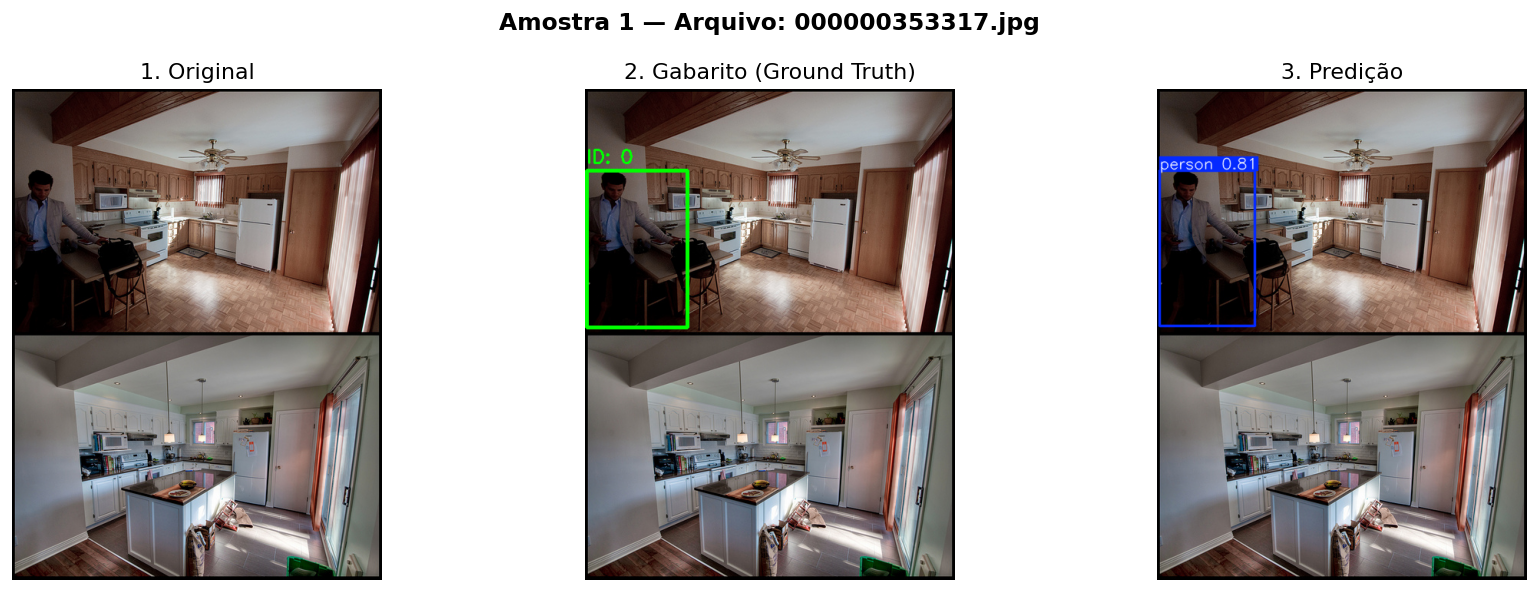

----------------------------------------------------------------------




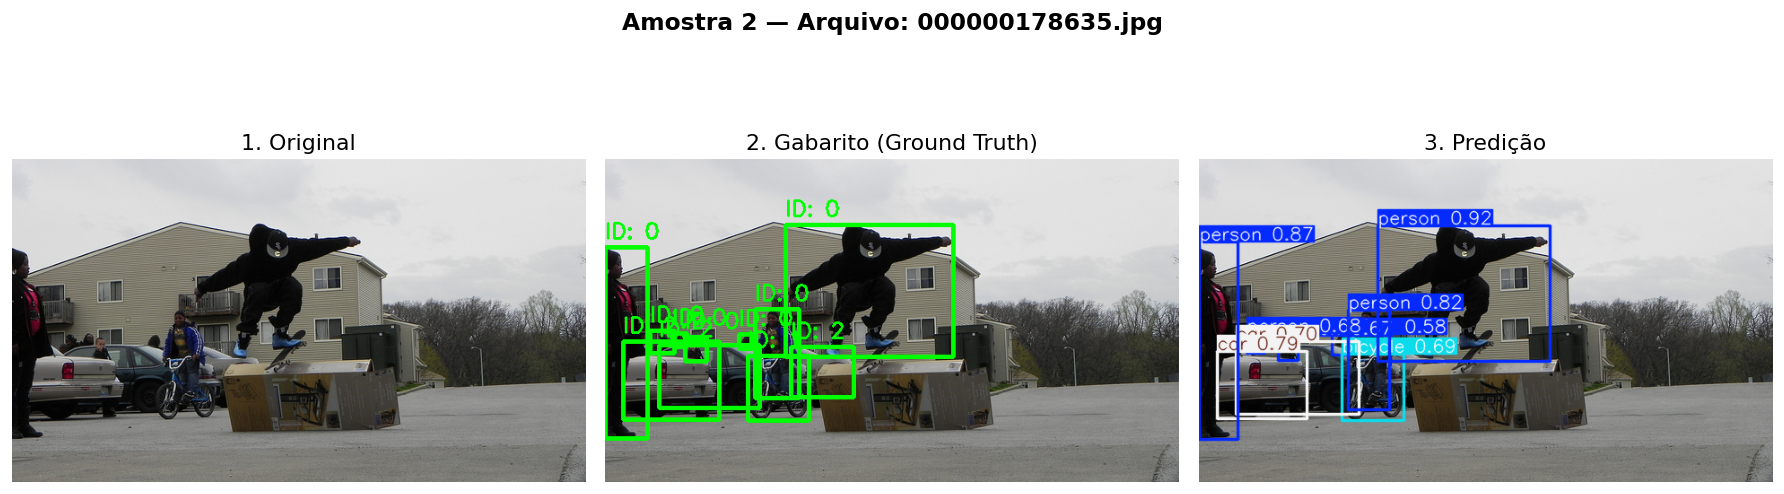

----------------------------------------------------------------------




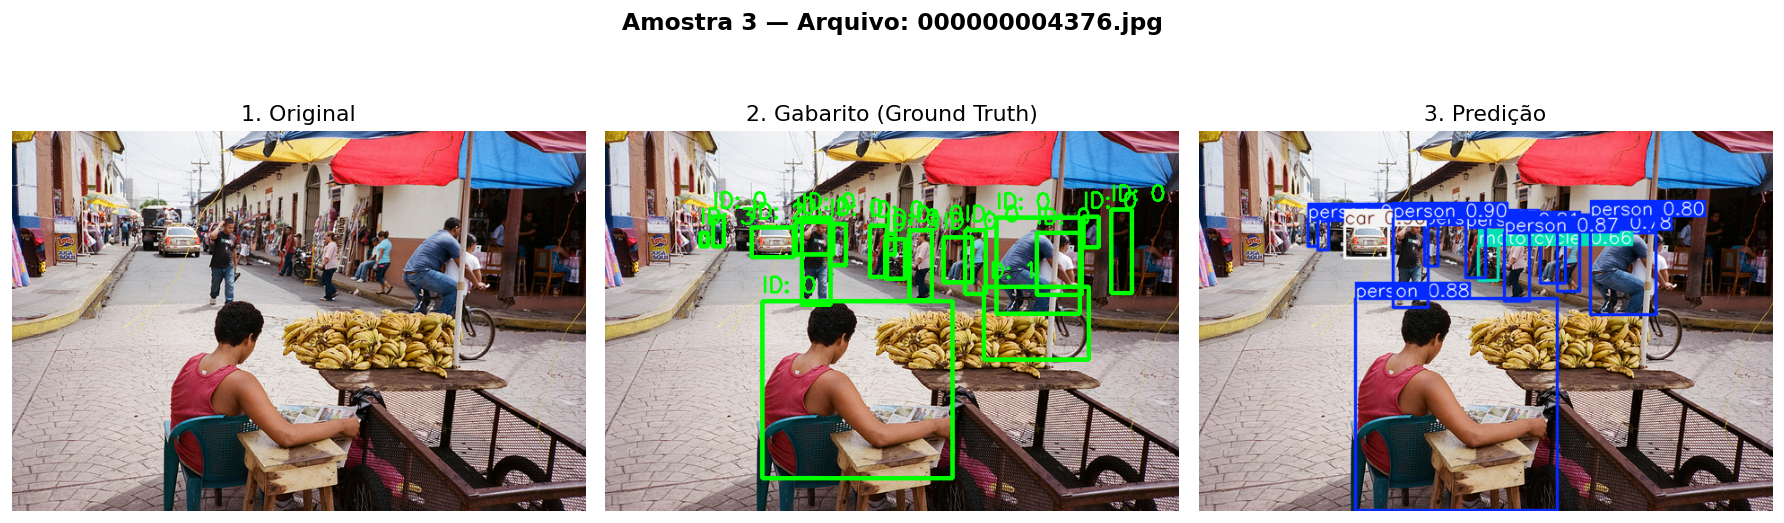

----------------------------------------------------------------------



✅ Processo finalizado com sucesso!


In [8]:
from IPython.display import display, Image
import matplotlib.pyplot as plt
import cv2
import os
import glob
import random
import datetime
import torch

print("\n>>> GERANDO AMOSTRAS COMPARATIVAS (YOLOv5)...")

# 1. Caminhos do Dataset e Modelo
pasta_base_dataset = "/content/Yolo_dataset"
diretorio_imagens_teste = f"{pasta_base_dataset}/images/test"
diretorio_labels_teste = f"{pasta_base_dataset}/labels/test"
caminho_modelo = f"{pasta_treino_drive}/weights/best.pt"

if not os.path.exists(caminho_modelo):
    print(f"❌ ERRO: Arquivo best.pt não encontrado em: {caminho_modelo}")
else:
    # --- AUDITORIA DE GARANTIA: NOME, CAMINHO E HORA ---
    nome_arquivo_modelo = os.path.basename(caminho_modelo)
    hora_mod = datetime.datetime.fromtimestamp(os.path.getmtime(caminho_modelo)).strftime('%H:%M:%S de %d/%m/%Y')

    print("-" * 70)
    print("✅ AUDITORIA DO PESO UTILIZADO:")
    print(f"📌 Nome:   {nome_arquivo_modelo}")
    print(f"📂 Caminho: {caminho_modelo}")
    print(f"🕒 Hora:   {hora_mod}")
    print("-" * 70)
    print("\n")

    # Carrega o modelo YOLOv5 nativo
    cwd_atual = os.getcwd()
    os.chdir('/content/yolov5')
    modelo_v5 = torch.hub.load('.', 'custom', path=caminho_modelo, source='local', force_reload=False)
    modelo_v5.conf, modelo_v5.iou = 0.5, 0.5
    os.chdir(cwd_atual)

def desenhar_gabarito(img, caminho_label):
    h, w = img.shape[:2]
    if os.path.exists(caminho_label):
        with open(caminho_label, 'r') as f:
            for linha in f:
                partes = linha.strip().split()
                if len(partes) >= 5:
                    cls_id = int(partes[0])
                    cx, cy, bw, bh = map(float, partes[1:5])
                    x1, y1 = int((cx - bw / 2) * w), int((cy - bh / 2) * h)
                    x2, y2 = int((cx + bw / 2) * w), int((cy + bh / 2) * h)
                    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
                    cv2.putText(img, f"ID: {cls_id}", (x1, max(y1-10, 20)),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def mostrar_amostras_separadas(dir_imgs, dir_labels, modelo_yolo, qtd_amostras=3):
    todas_imagens = glob.glob(f"{dir_imgs}/*.[jJ][pP][gG]") + glob.glob(f"{dir_imgs}/*.[pP][nN][gG]")
    if len(todas_imagens) < qtd_amostras:
        print(f"⚠️ Imagens insuficientes! Encontradas apenas {len(todas_imagens)}.")
        return

    amostras = random.sample(todas_imagens, qtd_amostras)

    for i, caminho_img in enumerate(amostras):
        nome_arquivo = os.path.basename(caminho_img)
        caminho_label = os.path.join(dir_labels, os.path.splitext(nome_arquivo)[0] + ".txt")

        # Processamento das imagens
        orig = cv2.cvtColor(cv2.imread(caminho_img), cv2.COLOR_BGR2RGB)
        gt = desenhar_gabarito(cv2.imread(caminho_img), caminho_label)

        resultados = modelo_yolo(caminho_img)
        resultados.render()
        pred = resultados.ims[0]

        # Layout minimalista de 1 linha por amostra
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        fig.suptitle(f"Amostra {i+1} — Arquivo: {nome_arquivo}", fontsize=14, fontweight='bold')

        axes[0].imshow(orig); axes[0].set_title("1. Original"); axes[0].axis('off')
        axes[1].imshow(gt);   axes[1].set_title("2. Gabarito (Ground Truth)"); axes[1].axis('off')
        axes[2].imshow(pred); axes[2].set_title("3. Predição"); axes[2].axis('off')

        plt.tight_layout()

        caminho_temp = f"/content/amostra_{i+1}.png"
        plt.savefig(caminho_temp, bbox_inches='tight', dpi=120)
        plt.close()

        display(Image(filename=caminho_temp))
        print("-" * 70)
        print("\n")

if 'modelo_v5' in locals():
    mostrar_amostras_separadas(diretorio_imagens_teste, diretorio_labels_teste, modelo_v5)

print("\n✅ Processo finalizado com sucesso!")